sample code to test integration

In [21]:
import pandas as pd
import numpy as np

from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_curve, auc 

from sklearn.model_selection import GridSearchCV

from sklearn.model_selection import train_test_split

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
%matplotlib inline

from numpy import loadtxt
import xgboost as xgb

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Going to use these 5 base models for the stacking
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier, 
                              GradientBoostingClassifier, ExtraTreesClassifier)
from sklearn.model_selection import KFold

from sklearn.naive_bayes import GaussianNB

import lightgbm as lgb
from sklearn.metrics import mean_squared_error

import matplotlib as mpl
from matplotlib import colors
from scipy import linalg
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [22]:
!kaggle --version

Kaggle CLI 2.2.4


In [23]:
import pandas as pd

train = pd.read_csv('./train_data.csv')
test = pd.read_csv('./test_data.csv')

train.output.value_counts()  

output
1    3873
0     711
Name: count, dtype: int64

In [24]:
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")

try:
    sample_solution = pd.read_csv("sample_solution.csv")
except:
    sample_solution = None

print("Train shape:", train.shape)
print("Test shape :", test.shape)

display(train.head())

Train shape: (4584, 670)
Test shape : (1732, 669)


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,...,z217,z218,z219,z220,z221,z222,subject,phase,state,output
0,0,0,0,1,-323.106605,2.694366,-1.987520,261.092784,0.013704,0.000100,...,-0.004930,-0.005554,5.246375,-7.534092,3.530736,-0.539045,K,3,C,1
1,0,0,0,1,-376.084691,0.969696,-6.933765,355.311648,0.030292,-0.000153,...,0.022757,0.052506,-3.727741,-2.854443,-0.699268,-0.054074,A,4,C,1
2,0,0,0,0,91.955425,2.621643,-2.581162,51.357206,0.036668,-0.000104,...,-0.086813,-0.101497,-7.510594,19.564182,-17.008130,4.945392,D,3,C,1
3,0,0,0,1,-391.814586,1.866914,-2.510799,382.900317,0.007947,-0.000028,...,0.030856,-0.161398,-6.435819,2.174453,-0.153956,-0.003958,G,2,C,0
4,0,0,0,0,-363.823732,2.951346,-3.726368,330.527539,0.010074,-0.000004,...,-0.017226,-0.016454,-2.581403,3.011932,-1.281361,0.192647,C,2,C,1


In [25]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 4584 entries, 0 to 4583
Columns: 670 entries, x1 to output
dtypes: float64(474), int64(194), str(2)
memory usage: 23.4 MB


In [26]:
print("\nColumns:")
print(train.columns.tolist())

print("\nMissing values:")
display(train.isnull().sum().sort_values(ascending=False).head(20))

print("\nUnique values:")
display(train.nunique().sort_values())


Columns:
['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x13', 'x14', 'x15', 'x16', 'x17', 'x18', 'x19', 'x20', 'x21', 'x22', 'x23', 'x24', 'x25', 'x26', 'x27', 'x28', 'x29', 'x30', 'x31', 'x32', 'x33', 'x34', 'x35', 'x36', 'x37', 'x38', 'x39', 'x40', 'x41', 'x42', 'x43', 'x44', 'x45', 'x46', 'x47', 'x48', 'x49', 'x50', 'x51', 'x52', 'x53', 'x54', 'x55', 'x56', 'x57', 'x58', 'x59', 'x60', 'x61', 'x62', 'x63', 'x64', 'x65', 'x66', 'x67', 'x68', 'x69', 'x70', 'x71', 'x72', 'x73', 'x74', 'x75', 'x76', 'x77', 'x78', 'x79', 'x80', 'x81', 'x82', 'x83', 'x84', 'x85', 'x86', 'x87', 'x88', 'x89', 'x90', 'x91', 'x92', 'x93', 'x94', 'x95', 'x96', 'x97', 'x98', 'x99', 'x100', 'x101', 'x102', 'x103', 'x104', 'x105', 'x106', 'x107', 'x108', 'x109', 'x110', 'x111', 'x112', 'x113', 'x114', 'x115', 'x116', 'x117', 'x118', 'x119', 'x120', 'x121', 'x122', 'x123', 'x124', 'x125', 'x126', 'x127', 'x128', 'x129', 'x130', 'x131', 'x132', 'x133', 'x134', 'x135', 'x136', 'x137', '

x1      0
y219    0
y221    0
y222    0
z1      0
z2      0
z3      0
z4      0
z5      0
z6      0
z7      0
z8      0
z9      0
z10     0
z11     0
z12     0
z13     0
z14     0
z15     0
y220    0
dtype: int64


Unique values:


x1         1
y57        1
y72        1
y73        1
y74        1
        ... 
y60     4584
y61     4584
y62     4584
y19     4584
y161    4584
Length: 670, dtype: int64

Class distribution:
output
1    3873
0     711
Name: count, dtype: int64

Class percentages:
output
1    84.489529
0    15.510471
Name: proportion, dtype: float64


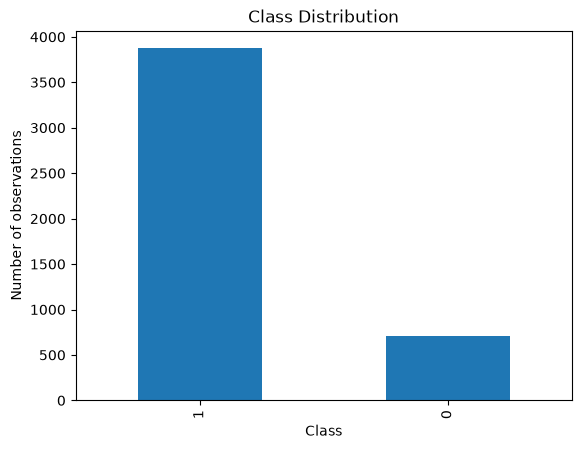

In [27]:
##Checking the class distribution and imbalance in the training data

print("Class distribution:")
print(train['output'].value_counts())

print("\nClass percentages:")
print(train['output'].value_counts(normalize=True) * 100)

train['output'].value_counts().plot(
    kind='bar',
    title='Class Distribution'
)

plt.xlabel("Class")
plt.ylabel("Number of observations")
plt.show()

In [28]:
# Separate features and target
X = train.drop(columns=['output'])
y = train['output']

# Stratified train-validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", X_train.shape)
print("Validation observations:", X_val.shape)

Training observations: (3667, 669)
Validation observations: (917, 669)


In [29]:
# Identify numerical and categorical columns
from sklearn.compose import ColumnTransformer


numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()


# Numeric preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# Categorical preprocessing
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])


# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

/var/folders/c3/1xdc_j3d5gnbhhnvrtwj5c540000gn/T/ipykernel_13600/89260283.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [30]:
baseline_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](669,)","['x1','x2','x3',...,'subject','phase','state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,669
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns 

In [31]:
# Predictions
baseline_pred = baseline_model.predict(X_val)

# Evaluation
baseline_accuracy = accuracy_score(y_val, baseline_pred)
baseline_precision = precision_score(
    y_val, baseline_pred, zero_division=0
)
baseline_recall = recall_score(
    y_val, baseline_pred, zero_division=0
)
baseline_f1 = f1_score(
    y_val, baseline_pred, zero_division=0
)

print("BASELINE MODEL PERFORMANCE")
print("--------------------------")
print(f"Accuracy : {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall   : {baseline_recall:.4f}")
print(f"F1 Score : {baseline_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, baseline_pred, zero_division=0))

BASELINE MODEL PERFORMANCE
--------------------------
Accuracy : 0.8451
Precision: 0.8451
Recall   : 1.0000
F1 Score : 0.9161

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       142
           1       0.85      1.00      0.92       775

    accuracy                           0.85       917
   macro avg       0.42      0.50      0.46       917
weighted avg       0.71      0.85      0.77       917



In [32]:
##Training a Logistic Regression model with class weights to handle class imbalance

logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        solver='lbfgs',
        C=1.0,
        random_state=42
    ))
])

In [33]:
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](669,)","['x1','x2','x3',...,'subject','phase','state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,669
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns 

In [34]:
# Predictions
logistic_pred = logistic_model.predict(X_val)

# Predicted probabilities for positive class
logistic_prob = logistic_model.predict_proba(X_val)[:, 1]

# Metrics
logistic_accuracy = accuracy_score(y_val, logistic_pred)

logistic_precision = precision_score(
    y_val, logistic_pred, zero_division=0
)

logistic_recall = recall_score(
    y_val, logistic_pred, zero_division=0
)

logistic_f1 = f1_score(
    y_val, logistic_pred, zero_division=0
)

logistic_auc = roc_auc_score(y_val, logistic_prob)

print("LOGISTIC REGRESSION PERFORMANCE")
print("-------------------------------")
print(f"Accuracy : {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall   : {logistic_recall:.4f}")
print(f"F1 Score : {logistic_f1:.4f}")
print(f"ROC-AUC  : {logistic_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, logistic_pred))

LOGISTIC REGRESSION PERFORMANCE
-------------------------------
Accuracy : 0.7328
Precision: 0.9288
Recall   : 0.7406
F1 Score : 0.8241
ROC-AUC  : 0.7908

Classification Report:
              precision    recall  f1-score   support

           0       0.33      0.69      0.44       142
           1       0.93      0.74      0.82       775

    accuracy                           0.73       917
   macro avg       0.63      0.72      0.63       917
weighted avg       0.84      0.73      0.77       917



In [35]:
comparison = pd.DataFrame({
    'Model': [
        'Baseline',
        'Logistic Regression'
    ],
    'Accuracy': [
        baseline_accuracy,
        logistic_accuracy
    ],
    'Precision': [
        baseline_precision,
        logistic_precision
    ],
    'Recall': [
        baseline_recall,
        logistic_recall
    ],
    'F1 Score': [
        baseline_f1,
        logistic_f1
    ]
})

display(comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,Baseline,0.845147,0.845147,1.000000,0.916076
1,Logistic Regression,0.732824,0.928803,0.740645,0.824121


In [41]:
# Train Logistic Regression on the entire training dataset
X_full = train.drop(columns=['output'])
y_full = train['output']

logistic_model.fit(X_full, y_full)

# Predict probabilities for the Kaggle test dataset
preds = logistic_model.predict_proba(test)

# Create submission DataFrame
submithis = pd.DataFrame([
    test.index,
    preds[:, 1]
]).T

submithis.columns = ['id', 'output']
submithis.id = submithis.id.astype(int)

display(submithis.head())

# Save submission
submithis.to_csv('submission_logistic.csv', index=False)

print("Submission file created successfully!")

,id,output
0,0,0.161697
1,1,0.960852
2,2,0.536888
3,3,0.661943
4,4,0.675553


Submission file created successfully!


In [42]:
##Generate learning curves for the logistic regression model
from sklearn.model_selection import StratifiedKFold

# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Training dataset sizes
train_sizes = np.linspace(0.1, 1.0, 8)

# Calculate learning curves
train_sizes_abs, train_scores, val_scores = learning_curve(
    estimator=logistic_model,
    X=X_train,
    y=y_train,
    train_sizes=train_sizes,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

# Mean scores
train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

# Standard deviations
train_std = np.std(train_scores, axis=1)
val_std = np.std(val_scores, axis=1)

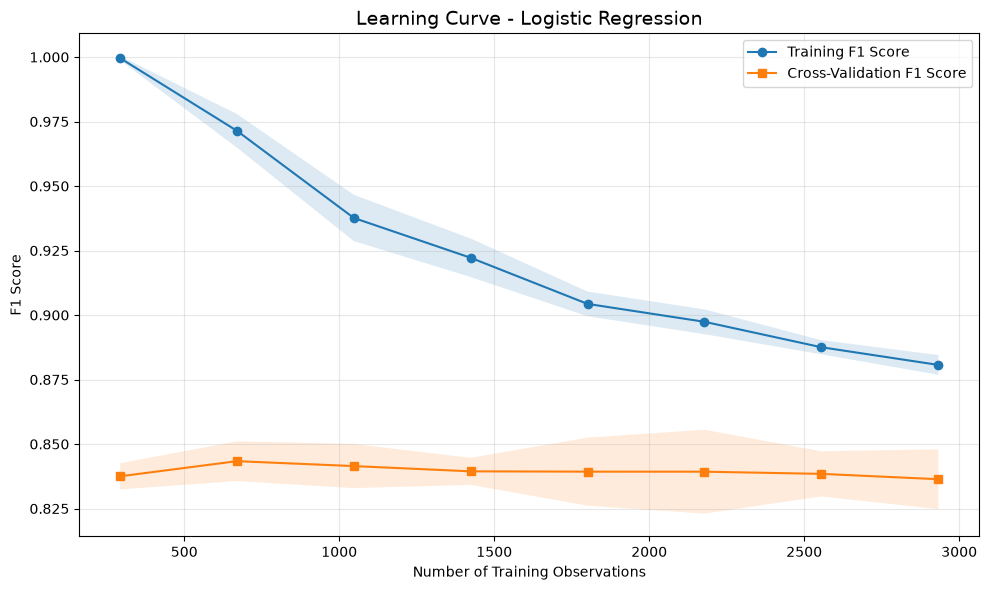

In [43]:
##Generate learning curve plot

plt.figure(figsize=(10, 6))

# Training curve
plt.plot(
    train_sizes_abs,
    train_mean,
    marker='o',
    label='Training F1 Score'
)

# Validation curve
plt.plot(
    train_sizes_abs,
    val_mean,
    marker='s',
    label='Cross-Validation F1 Score'
)

# Training variance
plt.fill_between(
    train_sizes_abs,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

# Validation variance
plt.fill_between(
    train_sizes_abs,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.15
)

plt.title(
    'Learning Curve - Logistic Regression',
    fontsize=14
)

plt.xlabel('Number of Training Observations')
plt.ylabel('F1 Score')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [44]:
def diagnose_model(
    train_scores,
    val_scores,
    gap_threshold=0.10,
    low_score_threshold=0.60
):

    train_f1 = np.mean(train_scores[-3:])
    val_f1 = np.mean(val_scores[-3:])

    gap = train_f1 - val_f1

    print("MODEL DIAGNOSTICS")
    print("------------------------------")
    print(f"Training F1   : {train_f1:.4f}")
    print(f"Validation F1 : {val_f1:.4f}")
    print(f"Gap           : {gap:.4f}")

    if gap > gap_threshold:

        print("\nDiagnosis: Possible OVERFITTING")
        print("Training performance is considerably higher.")
        print("Consider stronger regularization or more data.")

    elif (
        train_f1 < low_score_threshold
        and val_f1 < low_score_threshold
    ):

        print("\nDiagnosis: Possible UNDERFITTING")
        print("Both training and validation scores are low.")
        print("Consider feature engineering or a more flexible model.")

    else:

        print("\nDiagnosis: No obvious severe overfitting.")
        print("Assess performance against your baseline.")

In [45]:
diagnose_model(
    train_mean,
    val_mean
)

MODEL DIAGNOSTICS
------------------------------
Training F1   : 0.8885
Validation F1 : 0.8380
Gap           : 0.0505

Diagnosis: No obvious severe overfitting.
Assess performance against your baseline.
